<a href="https://colab.research.google.com/github/sutherlandnele/suthzy-colab-ai-machine-learning-python/blob/main/suthzy_ai_ml_supv_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler
from google.colab import drive
import copy
import seaborn as sns
import tensorflow as tf
from sklearn.linear_model import LinearRegression



#Dataset:

#Seoul Bike Sharing Demand [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5F62R.

In [17]:
drive.mount('/content/drive')

# We will use these to rename the remaining 11 columns after dropping the 3 unwanted ones
dataset_cols = [
    "bike_count",
    "hour",
    "temp",
    "humidity",
    "wind",
    "visibility",
    "dew_pt_temp",
    "radiation",
    "rain",
    "snow",
    "functional"
]

# Load with encoding to handle special characters (like degree symbols in headers)
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/SeoulBikeData.csv', encoding='unicode_escape')

# Drop the unwanted columns using their actual CSV header names
df = df.drop(["Date", "Holiday", "Seasons"], axis=1)

# Assign the custom simplified names to the remaining 11 columns
df.columns = dataset_cols
df["functional"] = df["functional"].map({"Yes": 1, "No": 0})
df = df[df['hour'] == 12]
df = df.drop(["hour"], axis=1)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df.head()

,bike_count,temp,humidity,wind,visibility,dew_pt_temp,radiation,rain,snow,functional
12,449,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,1
36,479,4.3,41,1.3,1666,-7.8,1.09,0.0,0.0,1
60,333,5.8,85,1.7,349,3.4,0.43,0.0,0.0,1
84,393,-0.3,38,4.8,1823,-12.9,1.11,0.0,0.0,1
108,321,-2.3,25,0.0,1962,-19.7,0.00,0.0,0.0,1


In [5]:
df = df.drop(['wind', 'visibility', 'functional'], axis = 1)

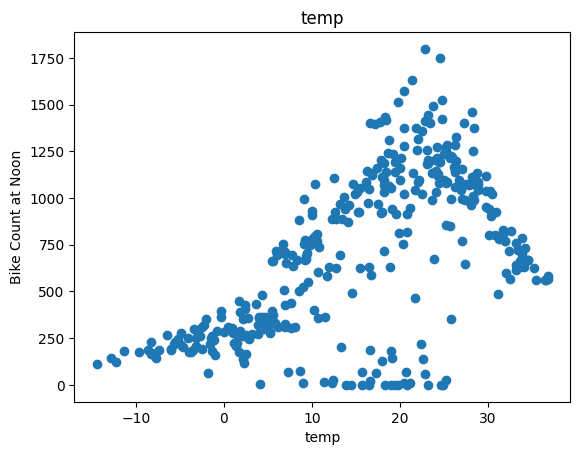

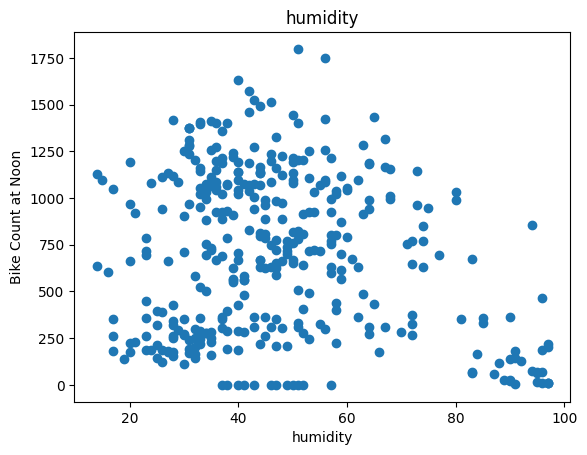

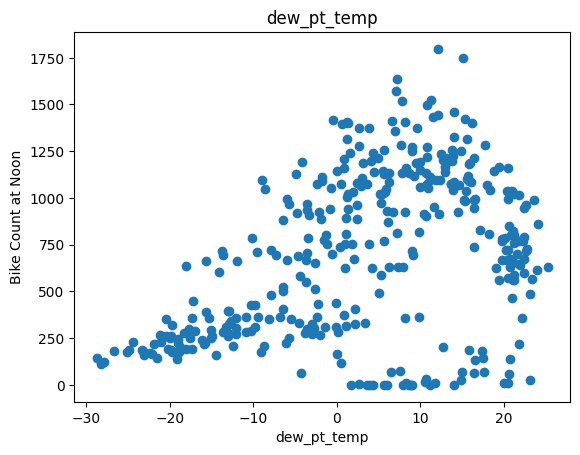

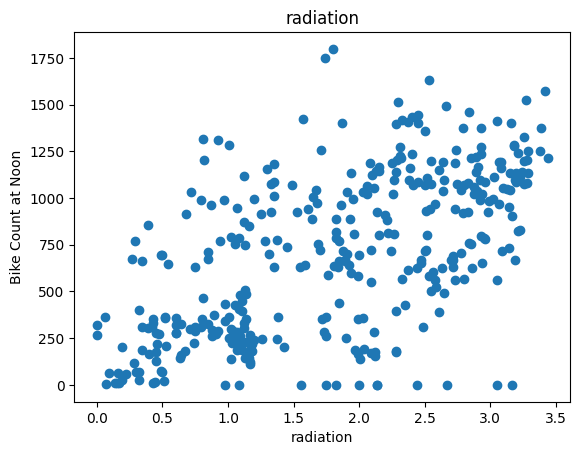

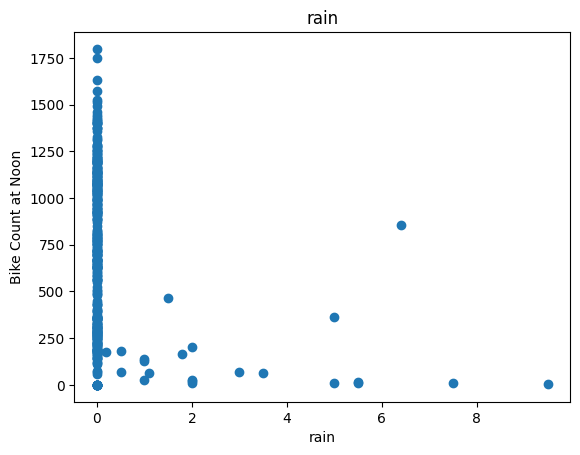

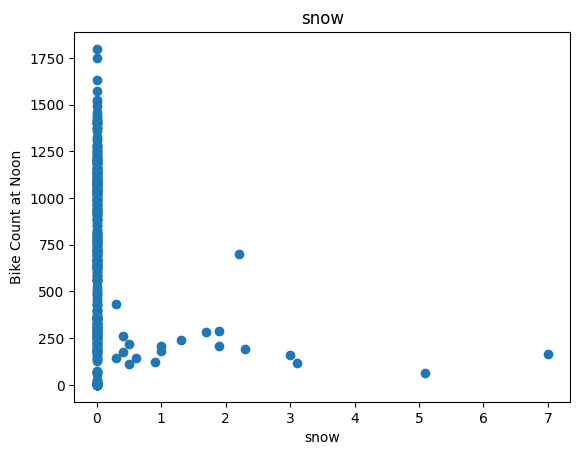

In [6]:
for label in df.columns[1:]:
  plt.scatter(df[label], df["bike_count"])
  plt.title(label)
  plt.ylabel("Bike Count at Noon")
  plt.xlabel(label)
  plt.show()

#Split dataset into Train/Valid/Test Datasets

In [7]:
train, val, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [27]:
def get_xy(dataframe, y_label, x_labels = None):

  dataframe = copy.deepcopy(dataframe)

  if x_labels is None:

    X = dataframe[[c for c in dataframe.columns if c != y_label]].values

  else:

    if len(x_labels) == 1:

      X = dataframe[[x_labels[0]]].values.reshape(-1, 1)

    else:

      X = dataframe[x_labels].values

  y = dataframe[y_label].values.reshape(-1, 1)

  data = np.hstack((X, y))

  return data, X, y



In [9]:
_, X_train_temp, y_train_temp = get_xy(train, "bike_count", x_labels=["temp"])
_, X_val_temp, y_val_temp = get_xy(val, "bike_count", x_labels=["temp"])
_, X_test_temp, y_test_temp = get_xy(test, "bike_count", x_labels=["temp"])

In [10]:
temp_reg = LinearRegression()
temp_reg.fit(X_train_temp, y_train_temp)

LinearRegression()

In [11]:
temp_reg.score(X_test_temp, y_test_temp)

0.29853972932753703

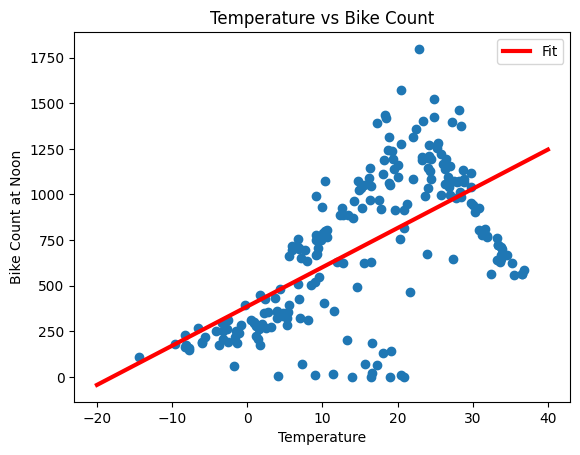

In [12]:
plt.scatter(X_train_temp, y_train_temp)
x = tf.linspace(-20, 40, 100)
plt.plot(x, temp_reg.predict(np.array(x).reshape(-1,1)), label="Fit", color="red", linewidth=3)
plt.legend()
plt.title("Temperature vs Bike Count")
plt.ylabel("Bike Count at Noon")
plt.xlabel("Temperature")
plt.show()

#Multiple Linear Regression

In [22]:
print(df.columns.to_list())

['bike_count', 'temp', 'humidity', 'wind', 'visibility', 'dew_pt_temp', 'radiation', 'rain', 'snow', 'functional']


In [28]:
train, val, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

_, X_train_all, y_train_all = get_xy(train, "bike_count", x_labels = df.columns[1:])
_, X_val_all, y_val_all = get_xy(val, "bike_count", x_labels = df.columns[1:])
_, X_test_all, y_test_all = get_xy(test, "bike_count", x_labels = df.columns[1:])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [29]:
all_reg = LinearRegression()
all_reg.fit(X_train_all, y_train_all)

LinearRegression()

In [30]:
all_reg.score(X_test_all, y_test_all)

0.616729651427188

#Regression with Neural Net

In [35]:
def plot_loss(history):

  plt.plot(history.history['loss'], label='loss')
  plt.plot(history.history['val_loss'], label='val_loss')
  plt.xlabel('Epoch')
  plt.ylabel('MSE')
  plt.legend()
  plt.grid(True)
  plt.show()


In [31]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=(1,),axis=None)
temp_normalizer.adapt(X_train_temp.reshape(-1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [32]:
temp_nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(units=1)
])

In [33]:
temp_nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss=tf.keras.losses.MeanSquaredError()
)

In [34]:
history = temp_nn_model.fit(
    X_train_temp.reshape(-1), y_train_temp,
    epochs=1000,
    verbose=0,
    validation_data=(X_val_temp, y_val_temp)
)

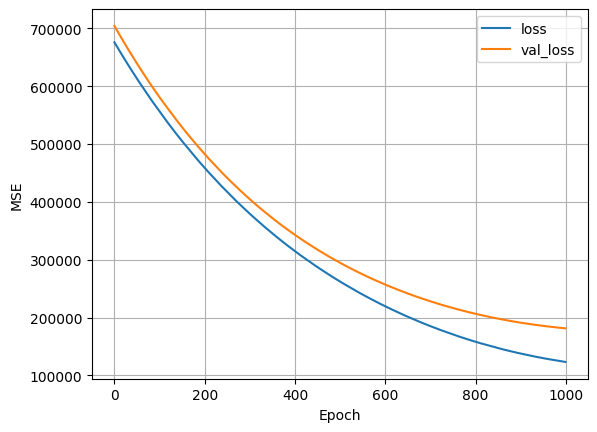

In [36]:
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


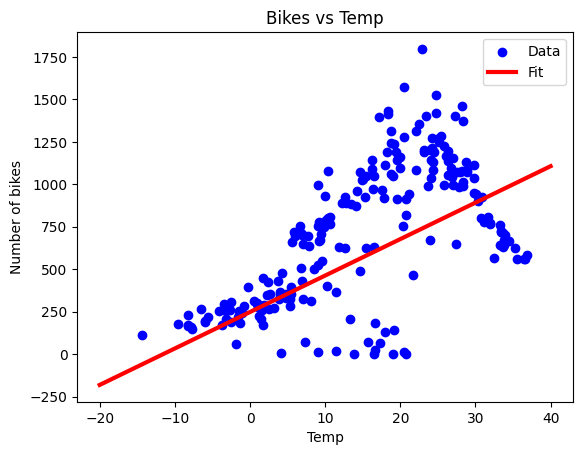

In [38]:
plt.scatter(X_train_temp, y_train_temp, label="Data", color="blue")
x = tf.linspace(-20, 40, 100)
plt.plot(x, temp_nn_model.predict(np.array(x).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.legend()
plt.title("Bikes vs Temp")
plt.ylabel("Number of bikes")
plt.xlabel("Temp")
plt.show()


### Multiple Variable Linear Regression with Neural Networks

First, we create a normalization layer and adapt it to the multi-feature training dataset `X_train_all`.

In [39]:
# 1. Create and adapt a multi-variable normalizer
# The input shape is now configured for the number of features in X_train_all (9 features)
all_normalizer = tf.keras.layers.Normalization(input_shape=(X_train_all.shape[1],), axis=-1)
all_normalizer.adapt(X_train_all)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Next, we build, compile, and train our multi-variable model.

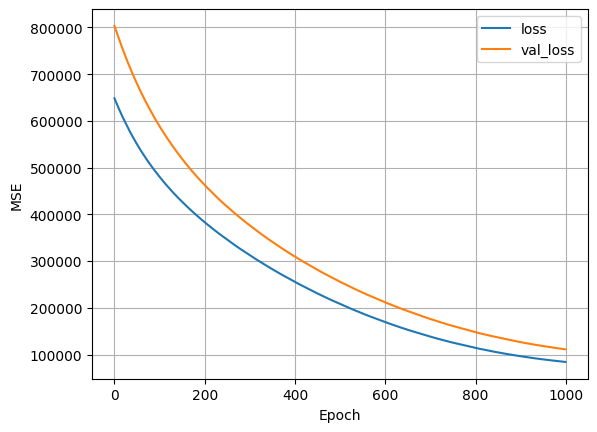

In [40]:
# 2. Build the multi-variable model
all_nn_model = tf.keras.Sequential([
    all_normalizer,
    tf.keras.layers.Dense(units=1)
])

# 3. Compile the model
all_nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss=tf.keras.losses.MeanSquaredError()
)

# 4. Fit the model
history_all = all_nn_model.fit(
    X_train_all, y_train_all,
    epochs=1000,
    verbose=0,
    validation_data=(X_val_all, y_val_all)
)

# Plot the training and validation loss
plot_loss(history_all)

#Using Real Neural Net with Multiple Nodes

In [64]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=(1,),axis=None)
temp_normalizer.adapt(X_train_temp.reshape(-1))

nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.MeanSquaredError()
)

In [65]:
history = nn_model.fit(
    X_train_temp, y_train_temp,
    epochs=100,
    verbose=0,
    validation_data=(X_val_temp, y_val_temp)
)



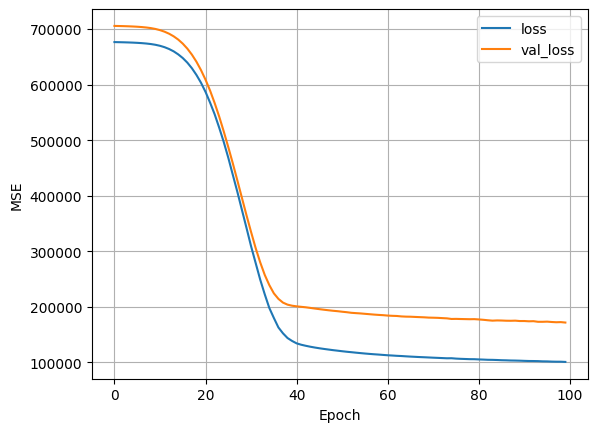

In [66]:
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


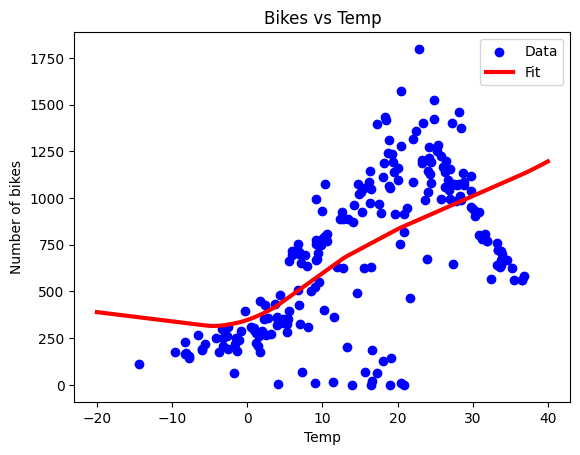

In [67]:
plt.scatter(X_train_temp, y_train_temp, label="Data", color="blue")
x = tf.linspace(-20, 40, 100)
plt.plot(x, nn_model.predict(np.array(x).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.legend()
plt.title("Bikes vs Temp")
plt.ylabel("Number of bikes")
plt.xlabel("Temp")
plt.show()

In [86]:
all_normalizer = tf.keras.layers.Normalization(input_shape=(X_train_all.shape[1],),axis=-1)
all_normalizer.adapt(X_train_all)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [87]:
nn_model = tf.keras.Sequential([
    all_normalizer,
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.MeanSquaredError()
)

In [88]:
history = nn_model.fit(
    X_train_all,
    y_train_all,
    epochs=100,
    verbose=0,
    validation_data=(X_val_all, y_val_all)
)

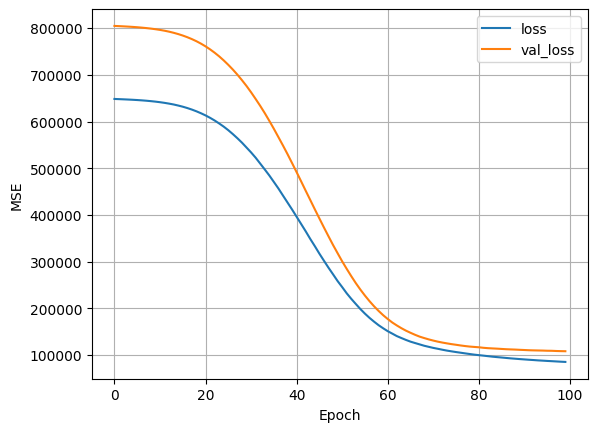

In [89]:
plot_loss(history)

In [91]:
# calculate the MSE for both linear reg and nn
y_pred_lr = all_reg.predict(X_test_all)
y_pred_nn = nn_model.predict(X_test_all)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


In [92]:
def MSE(y_pred, y_real):
  return np.square(y_pred - y_real).mean()

In [93]:
MSE(y_pred_lr, y_test_all)

np.float64(68613.83354817014)

In [94]:
MSE(y_pred_nn, y_test_all)

np.float64(89647.46677641106)

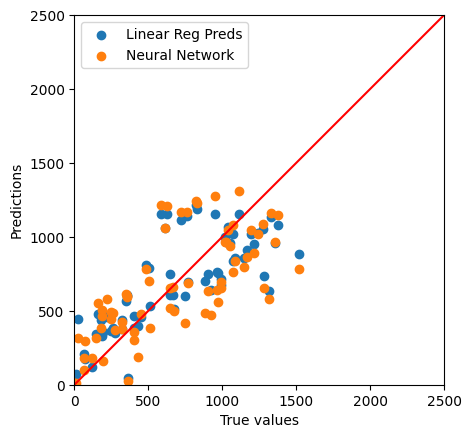

In [95]:
ax = plt.axes(aspect='equal')
plt.scatter(y_test_all, y_pred_lr,label='Linear Reg Preds')
plt.scatter(y_test_all, y_pred_nn,label='Neural Network')
plt.xlabel('True values')
plt.ylabel('Predictions')
lims = [0, 2500]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, c="red")
plt.legend()
plt.show()